In [ ]:
import sys

import numpy as np 
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [3]:
def analyze_stability(delta, gamma):
    J = np.array([[0, 1],
                  [-gamma, -2 * delta]])

    eigenvalues, eigenvectors = np.linalg.eig(J)
    lam1, lam2 = eigenvalues

    if np.isclose(lam1.imag, 0) and np.isclose(lam2.imag, 0):
        lam1, lam2 = lam1.real, lam2.real
        if lam1 < 0 and lam2 < 0:
            stability = "Устойчивый узел"
            color_point = 'blue'
        elif lam1 > 0 and lam2 > 0:
            stability = "Неустойчивый узел"
            color_point = 'red'
        elif lam1 * lam2 < 0:
            stability = "Седло"
            color_point = 'red'
        else:
            stability = "Негрубое равновесие"
            color_point = 'green'
    else:
        real_part = lam1.real
        if np.isclose(real_part, 0):
            stability = "Центр"
            color_point = 'green'
        elif real_part < 0:
            stability = "Устойчивый фокус"
            color_point = 'blue'
        else:
            stability = "Неустойчивый фокус"
            color_point = 'red'

    return {
        "stability": stability,
        "eigenvalues": eigenvalues,
        "eigenvectors": eigenvectors,
        "color_point": color_point
    }

In [ ]:
def plot_separatrices_integrated(rhs, analysis, L=5.0):
    if analysis["stability"] in ("Устойчивый фокус", "Неустойчивый фокус", "Центр", "Негрубое равновесие"):
        return

    eigenvalues = analysis["eigenvalues"].real
    eigenvectors = analysis["eigenvectors"].real
    

    for i, lam in enumerate(eigenvalues):
        vec = eigenvectors[:, i]
        vec = vec / np.linalg.norm(vec)
        color = 'blue' if lam < 0 else 'red'
        
        for sign in [1, -1]:
            y0 =  sign* L * vec
            
        

            
            sol = solve_ivp(rhs, (0, 50), y0, max_step=0.05)
            sol2 = solve_ivp(rhs, (0, -50), y0, max_step=0.05)
            plt.plot(sol.y[0], sol.y[1], color=color, lw=1, zorder=4)
            plt.plot(sol2.y[0], sol2.y[1], color=color, lw=1, zorder=4)

            arrows = sign*  vec

            if (color == "blue"):
                plt.quiver(0.5*arrows[0], 0.5*arrows[1], -arrows[0], -arrows[1], color = color)
            else:
                plt.quiver(0.5*arrows[0], 0.5*arrows[1], arrows[0], arrows[1], color = color)


In [98]:
def f1(gamma, delta): #делаем замыкание
    def rhs(t, y):
        x, v = y
        return [v, -gamma * x - 2 * delta * v] 
    return rhs


In [ ]:
def plot_vector_field(rhs, limits, N=20):
    xlims, ylims = limits
    xs = np.linspace(xlims[0], xlims[1], N)
    ys = np.linspace(ylims[0], ylims[1], N)
    X, Y = np.meshgrid(xs, ys)
    
    U, V = np.zeros_like(X), np.zeros_like(Y)
    for i in range(N):
        for j in range(N):
            U[i, j], V[i, j] = rhs(0.0, [X[i, j], Y[i, j]])
            
    norm = np.hypot(U, V) #длина 
    norm[norm == 0] = 1 

    U, V = U / norm, V / norm

    plt.quiver(X, Y, U, V, alpha=0.3)

def plot_trajectories(rhs, starts, T=10):

    for y0 in starts: 
        sol_fw = solve_ivp(rhs, (0, T), y0, method="RK45", rtol=1e-10)
        plt.plot(sol_fw.y[0], sol_fw.y[1], color='black', lw=1)
        
        sol_bw = solve_ivp(rhs, (0, -T), y0, method="RK45", rtol=1e-10)
        plt.plot(sol_bw.y[0], sol_bw.y[1], color='black', lw=1)

Параметры:           delta = 0.5, gamma = 2.0
Тип равновесия:      Устойчивый фокус
Цвет точки:          blue
Собственные числа:   λ1 = -0.5+1.32288j
                     λ2 = -0.5-1.32288j
Собственные векторы: v1 = (-0.204124-0.540062j, 0.816497+0j)
                     v2 = (-0.204124+0.540062j, 0.816497-0j)


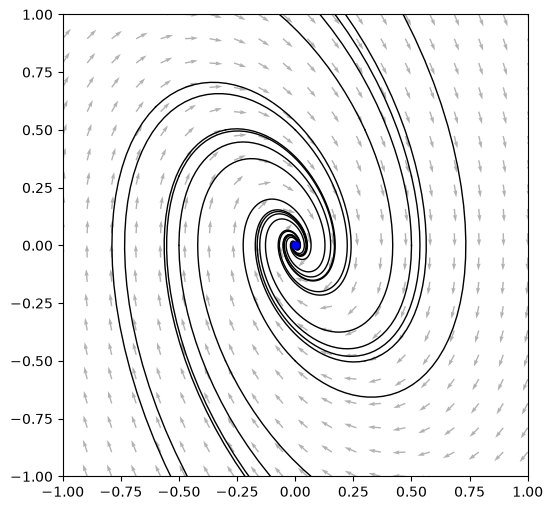

Параметры:           delta = 2.0, gamma = 1.0
Тип равновесия:      Устойчивый узел
Цвет точки:          blue
Собственные числа:   λ1 = -0.267949+0j
                     λ2 = -3.73205+0j
Собственные векторы: v1 = (0.965926+0j, -0.258819+0j)
                     v2 = (-0.258819+0j, 0.965926+0j)


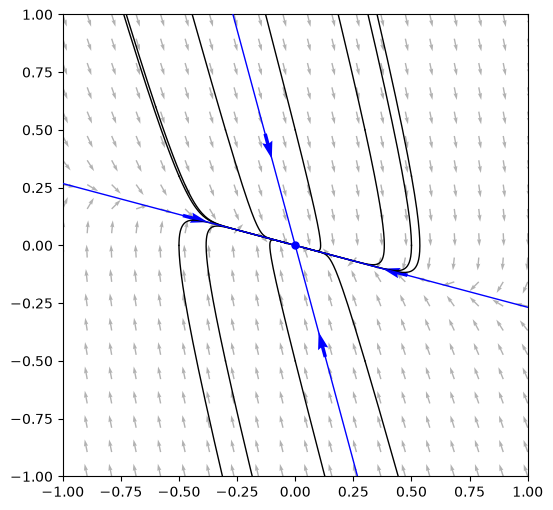

Параметры:           delta = 0.0, gamma = 1.0
Тип равновесия:      Центр
Цвет точки:          green
Собственные числа:   λ1 = 0+1j
                     λ2 = -0-1j
Собственные векторы: v1 = (0.707107+0j, 0+0.707107j)
                     v2 = (0.707107-0j, 0-0.707107j)


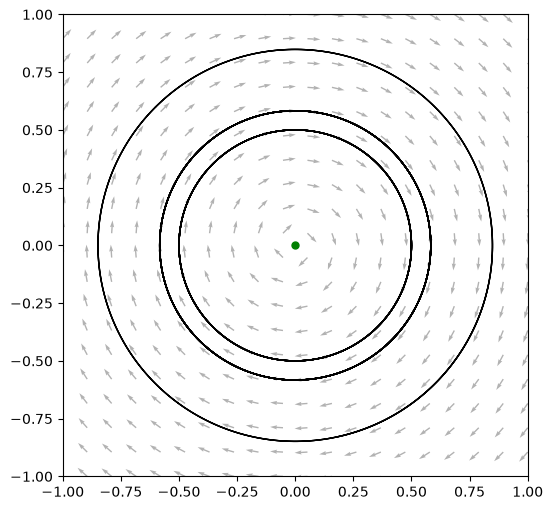

Параметры:           delta = -0.5, gamma = 2.0
Тип равновесия:      Неустойчивый фокус
Цвет точки:          red
Собственные числа:   λ1 = 0.5+1.32288j
                     λ2 = 0.5-1.32288j
Собственные векторы: v1 = (-0.204124+0.540062j, -0.816497+0j)
                     v2 = (-0.204124-0.540062j, -0.816497-0j)


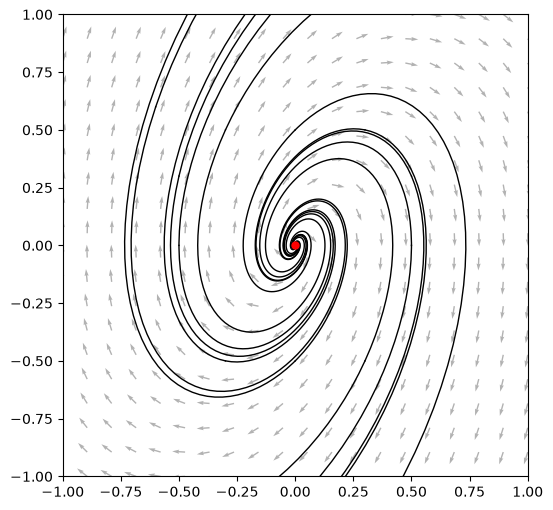

Параметры:           delta = -2.0, gamma = 1.0
Тип равновесия:      Неустойчивый узел
Цвет точки:          red
Собственные числа:   λ1 = 0.267949+0j
                     λ2 = 3.73205+0j
Собственные векторы: v1 = (-0.965926+0j, -0.258819+0j)
                     v2 = (-0.258819+0j, -0.965926+0j)


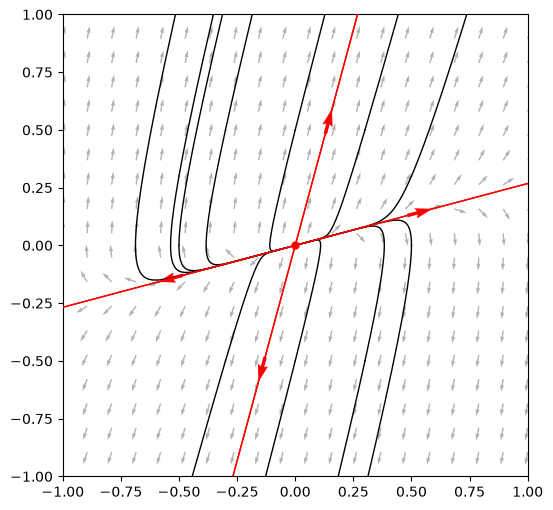

Параметры:           delta = 0.0, gamma = -1.0
Тип равновесия:      Седло
Цвет точки:          red
Собственные числа:   λ1 = 1+0j
                     λ2 = -1+0j
Собственные векторы: v1 = (0.707107+0j, 0.707107+0j)
                     v2 = (-0.707107+0j, 0.707107+0j)


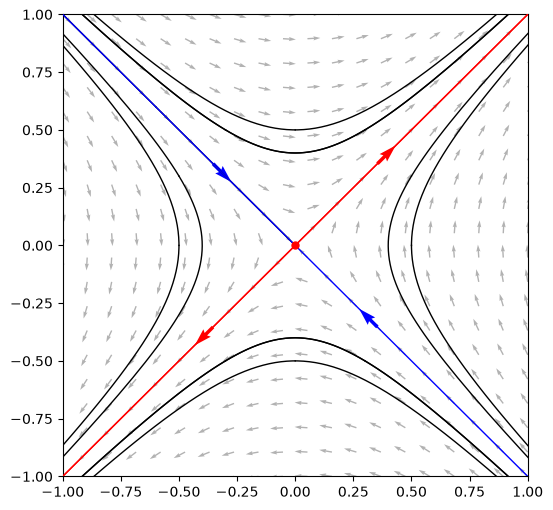

In [100]:
params = [(0.5, 2.0),(2.0, 1.0),(0.0, 1.0),(-0.5, 2.0),(-2.0, 1.0),(0.0, -1.0)]
starts = [(0.5,  0.3), (-0.5, 0.3), (0.3,  0.5), (-0.3,  0.5),(0.3, -0.5), (-0.3, -0.5), (-0.6, 0.6), (0,0.5), (0,-0.5), (-0.5,0), (0.5, 0)]
limits = [(-1, 1), (-1, 1)]
for delta, gamma in params:
    info = analyze_stability(delta, gamma)
    rhs  = f1(gamma, delta)

    print(f"Параметры:           delta = {delta}, gamma = {gamma}")
    print(f"Тип равновесия:      {info['stability']}")
    print(f"Цвет точки:          {info['color_point']}")
    print(f"Собственные числа:   λ1 = {info['eigenvalues'][0]:.6g}")
    print(f"                     λ2 = {info['eigenvalues'][1]:.6g}")

    ev1 = info["eigenvectors"][:, 0]
    ev2 = info["eigenvectors"][:, 1]
    print(f"Собственные векторы: v1 = ({ev1[0]:.6g}, {ev1[1]:.6g})")
    print(f"                     v2 = ({ev2[0]:.6g}, {ev2[1]:.6g})")

    fig, ax = plt.subplots(figsize=(6, 6))
    plot_vector_field(rhs, limits)
    plot_separatrices_integrated(rhs, info)
    plot_trajectories(rhs, starts)
    ax.plot(0, 0, 'o', color=info["color_point"], markersize=5, zorder=5)
    ax.set_xlim(limits[0])
    ax.set_ylim(limits[1])

    plt.show()     
    plt.close(fig)      
